# 03 - Exploratory data analysis and first models (preliminary report)

Input: `data/user_features.parquet` (201,335 users × 15 features, from notebook 02) and `data/services.parquet`.
Output: figures in `figures/` used in the preliminary report.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from mlxtend.frequent_patterns import apriori, association_rules

ROOT = Path.cwd().parent
OUT  = ROOT / "data"
FIG  = ROOT / "figures"; FIG.mkdir(exist_ok=True)

BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#898781"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9, "axes.titlesize": 11})

df = pd.read_parquet(OUT / "user_features.parquet")
COUNTS = ["n_posts", "n_sources", "n_comments_on_others", "n_comments_on_own", "n_comments_received",
          "n_likes_given", "n_likes_received", "n_followers", "n_following", "n_services"]
SHARES = ["pct_native", "pct_image", "pct_video"]
df.shape

(201335, 15)


- Loads the user feature table from 02_build_features: **201,335 users × 15 features** (one row per user who posted at least once between 1 Aug and 30 Sep 2010).
- Splits the features into two groups that need different treatment:
  - `COUNTS` (10 features): unbounded counts (0 … 166,965), heavily skewed - will be log-transformed.
  - `SHARES` (3 features): proportions between 0 and 1 (`pct_` = share of the user's posts that are native / contain an image / contain a video) - no log needed.
- `has_description` (binary) is not used in clustering: mixing a 0/1 attribute into Euclidean distance with numeric features is questionable.

### Histograms: raw vs log(1+x)

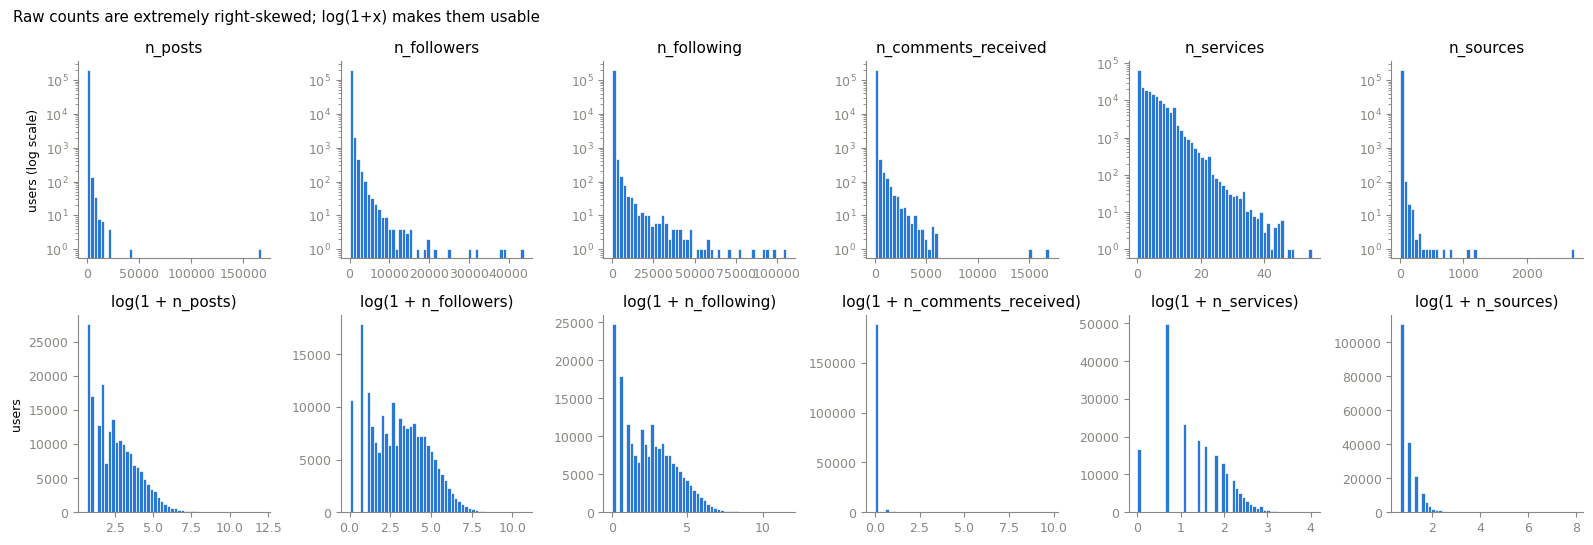

In [2]:
show = ["n_posts", "n_followers", "n_following", "n_comments_received", "n_services", "n_sources"]
fig, axes = plt.subplots(2, len(show), figsize=(16, 5.5))
for i, col in enumerate(show):
    axes[0, i].hist(df[col], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
    axes[0, i].set_title(col); axes[0, i].set_yscale("log")
    axes[1, i].hist(np.log1p(df[col]), bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
    axes[1, i].set_title(f"log(1 + {col})")
axes[0, 0].set_ylabel("users (log scale)"); axes[1, 0].set_ylabel("users")
fig.suptitle("Raw counts are extremely right-skewed; log(1+x) makes them usable", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "01_histograms.png", dpi=150)

**Findings – histograms**
- **Top row (raw values, y-axis on log scale):** almost all users fall in the first bin, with a few extreme values far to the right - **strongly right-skewed** distributions. Mean ≫ median: e.g. `n_posts` has median 10 but maximum 166,965 (≈ 2,700 posts per day - an automated account).
- **Bottom row (after `log1p(x) = ln(1 + x)`):** the distributions spread out and become usable. The `+1` is needed because ln(0) is undefined and many users have 0.
- `n_comments_received` stays a single spike at 0 even after the log: 94% of users have exactly 0 (zero-inflation).

**Why it matters:** k-means uses Euclidean distance, which squares differences - on raw counts a few extreme accounts would dominate every distance. **Decision: apply `log1p` to all count features before clustering.**

### Share features

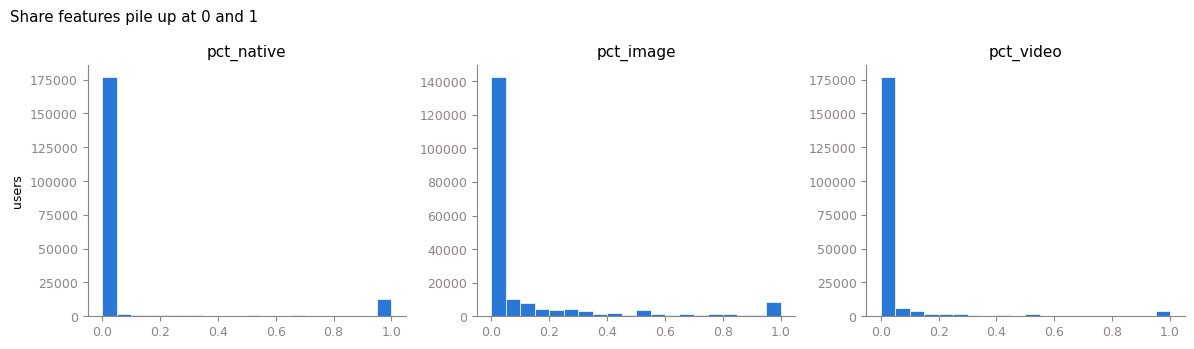

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, SHARES):
    ax.hist(df[col], bins=20, color=BLUE, edgecolor="white", linewidth=0.5); ax.set_title(col)
axes[0].set_ylabel("users")
fig.suptitle("Share features pile up at 0 and 1", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "02_share_histograms.png", dpi=150)

**Findings – share features**
- All three shares pile up at the extremes: most users have `pct_native = 0` (they **never** type posts directly on FriendFeed - everything comes from external tools), a smaller group has exactly 1 (everything typed by hand). Users rarely mix both ways of posting.
- `pct_image` and `pct_video` are 0 for most users; a small group posts (almost) only images or only videos.
- Shares are already bounded in [0, 1], so no log transform is needed; they are only standardized together with the other features.

### Box plots and share of zeros

n_likes_given           94.7
n_comments_on_others    93.8
n_comments_received     93.6
n_likes_received        92.2
n_comments_on_own       83.6
n_following             12.3
n_services               8.4
n_followers              5.3
n_sources                0.0
n_posts                  0.0
dtype: float64

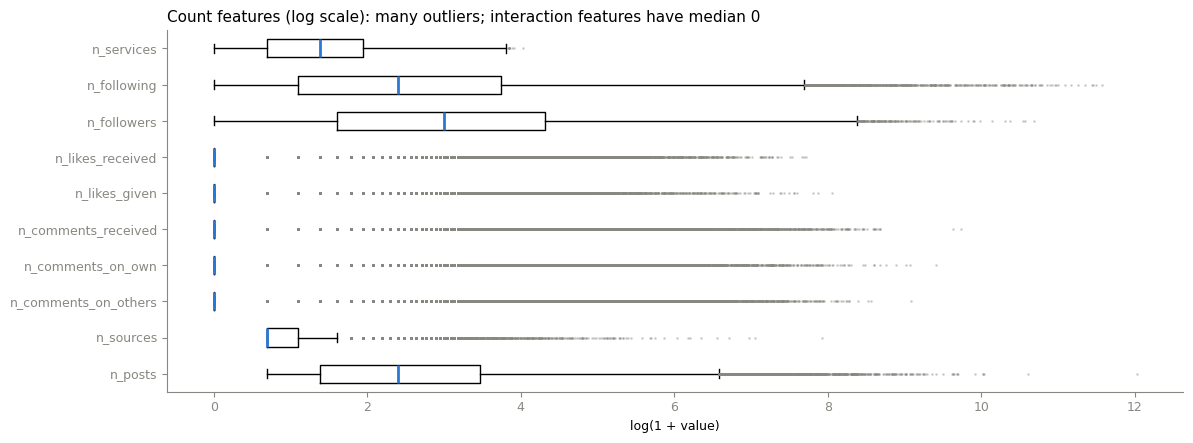

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.boxplot([np.log1p(df[c]) for c in COUNTS], vert=False, widths=0.5,
           flierprops=dict(marker=".", markersize=2, markerfacecolor=MUTED, markeredgecolor=MUTED, alpha=0.3),
           medianprops=dict(color=BLUE, linewidth=2))
ax.set_yticklabels(COUNTS)
ax.set_xlabel("log(1 + value)")
ax.set_title("Count features (log scale): many outliers; interaction features have median 0", loc="left")
fig.tight_layout(); fig.savefig(FIG / "03_boxplots.png", dpi=150)

zero_share = (df[COUNTS] == 0).mean().mul(100).round(1).sort_values(ascending=False)
zero_share

**Findings – box plots and zero shares**

*Reading a box plot:* the box spans Q1–Q3 (the middle 50% of users, width = IQR), the blue line is the median, whiskers reach 1.5 × IQR, dots beyond are outliers. Values shown on the log(1 + x) scale.

- `n_posts`, `n_followers`, `n_following`, `n_services`: proper boxes with long outlier tails.
- **Interaction features** (comments, likes): the box collapses to a line at 0 (Q1 = median = Q3 = 0), so **every user with at least one comment or like counts as an "outlier"**.
- Share of users with value 0: likes given 94.7%, comments on others 93.8%, comments received 93.6%, likes received 92.2%, comments on own posts 83.6%, following 12.3%, services 8.4%, followers 5.3%.

**Interpretation:** most users never interact - 81% of posters only post. Outliers are **not removed**: here they are the phenomenon of interest (very active or automated accounts). Their influence on distances is limited by the log transform instead.

### Correlations (Spearman, on log counts + shares)

n_comments_on_others  n_likes_given          0.761939
n_comments_received   n_likes_received       0.715771
n_comments_on_others  n_comments_received    0.668534
n_comments_received   n_likes_given          0.640300
n_followers           n_following            0.615431
n_likes_given         n_likes_received       0.611107
dtype: float64

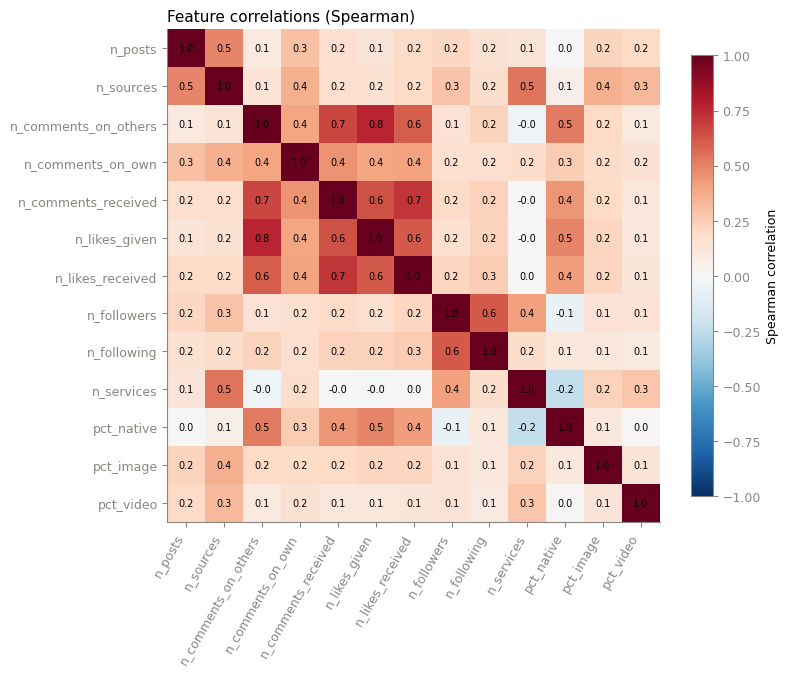

In [5]:
X = pd.concat([np.log1p(df[COUNTS]), df[SHARES]], axis=1)
corr = X.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Feature correlations (Spearman)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "04_correlation.png", dpi=150)

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs.sort_values(key=abs, ascending=False).head(6)

**Findings - correlations (Spearman)**
- Spearman correlation is computed on **ranks**, so it is robust to the extreme values in this data (unlike Pearson) and unaffected by the log transform.
- Strongest pairs: comments on others - likes given **0.76**, comments received - likes received **0.72**, comments on others - comments received **0.67**, followers - following **0.62**.
- The four interaction features (comments on others / received, likes given / received) measure largely the same thing: how socially active a user is.

**Why it matters:** Euclidean distance adds up differences feature by feature, so four correlated features count "interaction" four times and over-weight it in k-means.

### First k-means: choosing k (log1p → z-score, Euclidean distance)

,k,sse,silhouette
0,2,1.909459e+06,0.673326
1,3,1.624247e+06,0.191576
2,4,1.447163e+06,0.220192
3,5,1.282890e+06,0.246067
4,6,1.148021e+06,0.269680
5,7,1.042719e+06,0.219799
6,8,9.670341e+05,0.223113


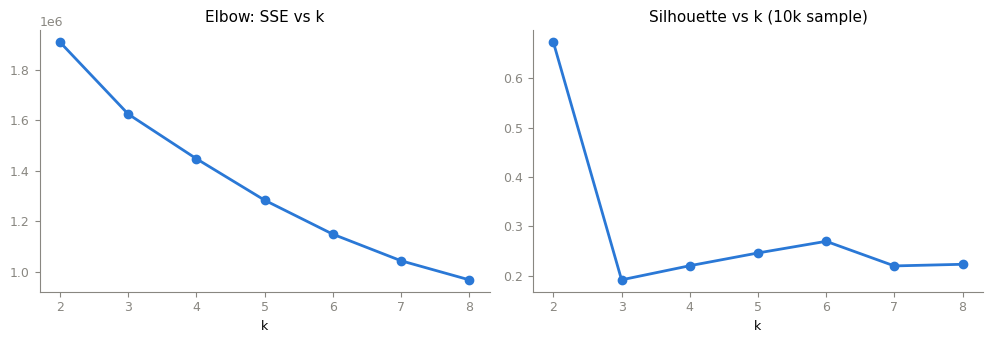

In [6]:
Xs = StandardScaler().fit_transform(X)
rng = np.random.default_rng(42)
sample = rng.choice(len(Xs), 10000, replace=False)

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    rows.append((k, km.inertia_, silhouette_score(Xs[sample], km.labels_[sample])))
res = pd.DataFrame(rows, columns=["k", "sse", "silhouette"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(res.k, res.sse, marker="o", color=BLUE, linewidth=2); axes[0].set_title("Elbow: SSE vs k"); axes[0].set_xlabel("k")
axes[1].plot(res.k, res.silhouette, marker="o", color=BLUE, linewidth=2); axes[1].set_title("Silhouette vs k (10k sample)"); axes[1].set_xlabel("k")
fig.tight_layout(); fig.savefig(FIG / "05_choose_k.png", dpi=150)
res

**Findings – first k-means run (k = 2 … 8)**

*Preprocessing:* `log1p` on counts (fixes skew) - z-score standardization (mean 0, std 1 per feature, so no feature dominates because of its units) - Euclidean distance. `n_init=10` restarts against bad local minima; `random_state=42` for reproducibility. Silhouette computed on a 10,000-user random sample (the full computation needs all pairwise distances, O(n²)).

| k | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|
| silhouette | **0.67** | 0.19 | 0.22 | 0.25 | 0.27 | 0.22 | 0.22 |

- **SSE has no clear elbow** - it decreases steadily.
- **k = 2 has the highest silhouette but is trivial:** it only separates the ~5,000 interactive users from everyone else (inflated by the four correlated interaction features - see notebook 04).
- For k ≥ 3 silhouettes are modest (0.19–0.27) - **cluster boundaries are soft**; the data is closer to a continuum than to well-separated groups.
- k = 4 was used as a **preliminary**

### k = 4: cluster profiles (medians)

In [7]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
df["cluster"] = km.labels_

profile = df.groupby("cluster")[COUNTS + SHARES].median().round(2)
profile.insert(0, "n_users", df["cluster"].value_counts().sort_index())
profile.T

cluster,0,1,2,3
n_users,13530.0,68933.00,5303.00,113569.0
n_posts,3.0,24.00,59.00,5.0
n_sources,1.0,3.00,3.00,1.0
n_comments_on_others,0.0,0.00,77.00,0.0
n_comments_on_own,0.0,0.00,39.00,0.0
n_comments_received,0.0,0.00,65.00,0.0
n_likes_given,0.0,0.00,20.00,0.0
n_likes_received,0.0,0.00,27.00,0.0
n_followers,3.0,80.00,151.00,8.0
n_following,7.0,35.00,130.00,5.0


**Findings – cluster profiles for k = 4 (medians)**

Medians, not means: within each cluster the features are still skewed, so the median describes the typical member; values are in original units (posts, followers), not z-scores.

| Cluster | Users | Posts | Native | Services | Followers | Comments on others | Preliminary name |
|---|---|---|---|---|---|---|---|
| 0 | 13,530 | 3 | 100% | 0 | 3 | 0 | Native casual users |
| 1 | 68,933 | 24 | 0% | 6 | 80 | 0 | Cross-posting broadcasters |
| 2 | 5,303 | 59 | 61% | 3 | 151 | 77 | Conversationalists |
| 3 | 113,569 | 5 | 0% | 2 | 8 | 0 | Low-activity automated posters |

- Conversation is concentrated in **2.6% of users** (cluster 2), who are also the most followed.
- Two automated groups differ in reach: many services and followers (1) vs low activity (3).
- With a silhouette of 0.22 these are tendencies rather than sharp groups.

PCA projection of the clusters (for visualisation only)

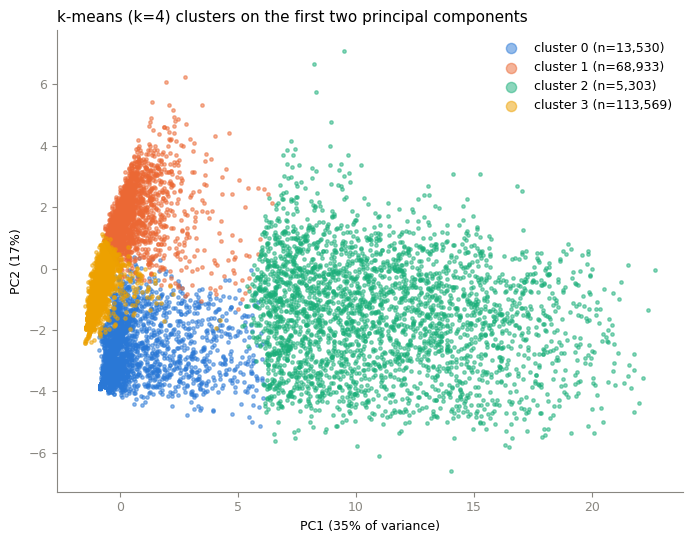

In [8]:
pca = PCA(n_components=2).fit(Xs)
P = pca.transform(Xs)

fig, ax = plt.subplots(figsize=(7, 5.5))
for c in range(K):
    idx = np.where(df["cluster"].values == c)[0]
    idx = rng.choice(idx, min(3000, len(idx)), replace=False)
    ax.scatter(P[idx, 0], P[idx, 1], s=6, alpha=0.5, color=CLUSTER_COLORS[c],
               label=f"cluster {c} (n={(df['cluster'] == c).sum():,})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(frameon=False, markerscale=3)
ax.set_title(f"k-means (k={K}) clusters on the first two principal components", loc="left")
fig.tight_layout(); fig.savefig(FIG / "06_pca_clusters.png", dpi=150)

**Findings – PCA projection (visualization only)**

PCA builds new uncorrelated axes as linear combinations of the features, ordered by how much variation they capture. The clustering itself used all 13 features; PCA is only used to draw them in 2D.

- PC1 explains **35%** and PC2 **17%** of the variance (52% together - 48% is not shown).
- PC1 is essentially the **interaction axis** (the correlated interaction features load on it), so the conversationalists (cluster 2) stretch far to the right and are clearly separated.
- Clusters 0, 1 and 3 overlap in this view - consistent with the modest silhouette. They may still be separated in dimensions not shown.
- At most 3,000 points per cluster are drawn to avoid over-plotting.

### First Apriori run: which services are linked together?

In [9]:
con = duckdb.connect()
b = con.sql(f"""
    SELECT s.user_id, s.service_id
    FROM '{(OUT / 'services.parquet').as_posix()}' AS s
    JOIN '{(OUT / 'users.parquet').as_posix()}'    AS u ON s.user_id = u.user_id
    WHERE u.type = 'user'
""").df()

basket = pd.crosstab(b["user_id"], b["service_id"]).astype(bool)
print("users with services:", basket.shape[0], "| services:", basket.shape[1])
print("share with only 1 service:", round((basket.sum(axis=1) == 1).mean(), 3))
print(basket.mean().sort_values(ascending=False).head(8).round(3))

basket2 = basket[basket.sum(axis=1) >= 2]
freq  = apriori(basket2, min_support=0.05, use_colnames=True, max_len=4)
rules = association_rules(freq, metric="confidence", min_threshold=0.5)
rules = rules[rules["lift"] > 1].sort_values("lift", ascending=False)
print(len(basket2), "baskets with >=2 services |", len(freq), "frequent itemsets |", len(rules), "rules")
rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10)

users with services: 305991 | services: 60
share with only 1 service: 0.35
service_id
twitter         0.805
blog            0.422
flickr          0.285
youtube         0.266
delicious       0.222
facebook        0.193
googletalk      0.162
googlereader    0.161
dtype: float64


198824 baskets with >=2 services | 348 frequent itemsets | 721 rules


,antecedents,consequents,support,confidence,lift
550,"(delicious, digg, twitter)",(stumbleupon),0.062628,0.531592,3.286376
162,"(delicious, digg)",(stumbleupon),0.069458,0.526999,3.257983
554,"(delicious, stumbleupon)","(digg, twitter)",0.062628,0.621823,3.254964
552,"(delicious, stumbleupon, twitter)",(digg),0.062628,0.700732,3.227742
164,"(delicious, stumbleupon)",(digg),0.069458,0.689638,3.176642
655,"(flickr, stumbleupon)","(digg, twitter)",0.050230,0.584856,3.061459
668,"(stumbleupon, youtube)","(digg, twitter)",0.056135,0.580244,3.037319
653,"(flickr, stumbleupon, twitter)",(digg),0.050230,0.651425,3.000625
666,"(stumbleupon, twitter, youtube)",(digg),0.056135,0.650484,2.996288
225,"(flickr, stumbleupon)",(digg),0.054737,0.637327,2.935686


**Findings – association rules on linked services (Question 2)**

*Representation:* one transaction per user = the set of external services they linked (binary user × service table via `pd.crosstab`). Population: all **305,991 individual users** with at least one linked service (services are a static snapshot, so the study window does not apply).

- **35%** of users link only one service. A one-item basket cannot produce a rule, so they are excluded - **198,824 baskets**.
- Item frequencies: Twitter **80.5%**, blog 42.2%, Flickr 28.5%, YouTube 26.6%, Delicious 22.2%.
- Apriori with **minsup = 5%** (every frequent itemset is backed by ≥ ~9,900 users), `max_len = 4` - **348 frequent itemsets**; rules with confidence ≥ 0.5 and lift > 1 - **721 rules**.

| Top rule | Support | Confidence | Lift |
|---|---|---|---|
| {digg, delicious} - {stumbleupon} | 0.069 | 0.53 | 3.26 |
| {delicious, stumbleupon} - {digg} | 0.069 | 0.69 | 3.18 |

**Interpretation:** Digg, Delicious and StumbleUpon - all social-bookmarking / link-sharing services - are adopted together: users of two of them are ~3× more likely than average to use the third. Many top rules are variations of the same itemset - closed/maximal itemsets would summarize them more compactly.

*Limitation of minsup = 5%:* rarely used services can never appear in a rule (rare-item problem).

### The Twitter trap: high confidence, lift ≈ 1

In [10]:
all_rules = association_rules(freq, metric="confidence", min_threshold=0.0)
to_twitter = all_rules[all_rules["consequents"] == frozenset({"twitter"})]
to_twitter.sort_values("confidence", ascending=False)[["antecedents", "consequents", "support", "confidence", "lift"]].head(5)

,antecedents,consequents,support,confidence,lift
1826,"(flickr, delicious, facebook)",(twitter),0.060134,0.926965,1.090628
1393,"(blog, digg, linkedin)",(twitter),0.050462,0.925468,1.088866
672,"(digg, facebook)",(twitter),0.066642,0.925021,1.088340
1785,"(delicious, digg, linkedin)",(twitter),0.050180,0.924652,1.087906
1841,"(delicious, facebook, youtube)",(twitter),0.057755,0.924408,1.087619


**Findings – the Twitter trap (confidence vs lift)**
- Rules predicting Twitter reach very high confidence, e.g. {digg, facebook} - {twitter}: **confidence 0.93**, but **lift only 1.09**.
- Twitter is linked by ~85% of these multi-service users anyway, so knowing that someone uses Digg and Facebook barely changes the chance they use Twitter - the rule is almost uninformative.
- **Confidence = P(Y | X) ignores how common Y is**; when Y is very frequent, almost any rule into Y has high confidence. **Lift = confidence / support(Y)** compares with that baseline (lift > 1: positive association; ≈ 1: independence).
- **Decision:** rules are ranked and filtered by **lift**, not confidence.